# FT Transformer Model Training & Model Evaluation

In [ ]:
import sys
import torch
import torch.nn as nn#
import numpy as np
from pathlib import Path
from skorch import NeuralNetClassifier
from skorch.callbacks import EarlyStopping

# Setup the project root directory paths safely
PROJECT_ROOT = r"C:\Users\shubh\projects\FairFraud"
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

# Import standardized pipeline and evaluation modules
from src.pipeline import get_data
from src.evaluation import evaluate_predictions

print("Fetching pipeline data splits...")
data = get_data()

X_train = data["X_train_dense"].astype(np.float32)
y_train = data["y_train"].astype(np.int64)
X_val = data["X_val_dense"].astype(np.float32)
y_val = data["y_val"].astype(np.int64)
X_test = data["X_test_dense"].astype(np.float32)
y_test = data["y_test"].astype(np.int64)

# Auto-detect processing device (GPU if available)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using active hardware device: {device}")

# Compute Inverse Frequency Weights for Cross-Entropy Loss Imbalance
class_counts = np.bincount(y_train)
total_samples = len(y_train)
weight_class_0 = total_samples / (2.0 * class_counts[0])
weight_class_1 = total_samples / (2.0 * class_counts[1])
ce_weights_tensor = torch.tensor([weight_class_0, weight_class_1], dtype=torch.float32).to(device)

# HIGHLY OPTIMIZED FAST FT-TRANSFORMER PYTORCH MODEL ARCHITECTURE
class FastFTTransformerModule(nn.Module):
    def __init__(self, in_features, d_token=32, n_blocks=3, n_heads=4, dropout=0.1):
        super().__init__()
        self.in_features = in_features
        self.d_token = d_token
        
        # Vectorized Tokenizer: Fast matrix math instead of a slow loop over features
        self.tokenizer = nn.Parameter(torch.randn(1, in_features, d_token))
        self.bias = nn.Parameter(torch.zeros(1, in_features, d_token))
        
        # Transformer Backbone Layers
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_token, nhead=n_heads, dim_feedforward=d_token * 4, 
            dropout=dropout, batch_first=True, activation='gelu'
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=n_blocks)
        
        # Linear Head Classifier
        self.ln = nn.LayerNorm(d_token * in_features)
        self.head = nn.Linear(d_token * in_features, 2)

    def forward(self, x):
        # x shape: [Batch, In_Features]
        # Vectorized feature tokenization step
        x = x.unsqueeze(-1) * self.tokenizer + self.bias  # Shape: [Batch, In_Features, d_token]
        
        # Pass embeddings through the transformer attention layers
        x = self.transformer(x)
        
        # Flatten attention outputs and map to classes [Batch, 2]
        x = x.flatten(start_dim=1)
        x = self.ln(x)
        return self.head(x)

# ==============================================================================
# 3. INITIALIZE AND TRAIN THE NETWORK VIA SKORCH ENGINE
# ==============================================================================
input_dim = X_train.shape[1]

model = NeuralNetClassifier(
    module=FastFTTransformerModule,
    module__in_features=input_dim,
    module__d_token=32,          
    module__n_blocks=3,          
    module__n_heads=4,           
    criterion=nn.CrossEntropyLoss,
    criterion__weight=ce_weights_tensor,  # Hardware-pinned class weights for 1.1% fraud imbalance
    optimizer=torch.optim.AdamW,
    optimizer__lr=1e-3,
    optimizer__weight_decay=1e-4,
    max_epochs=20,               
    batch_size=4096,             # Large batch processing optimized for 1M rows
    device=device,
    callbacks=[
        # Stops training early if validation loss stalls, preventing overfitting
        EarlyStopping(patience=5, monitor='valid_loss')
    ],
    verbose=1
)

print("Training FT-Transformer Network... (Processing Multi-Head Attention blocks)")
model.fit(X_train, y_train)

# GENERATE PREDICTIONS AND EVALUATE
print("Generating test predictions...")
test_probabilities = model.predict_proba(X_test)[:, 1]

Fetching pipeline data splits...
Using active hardware device: cuda
Training FT-Transformer Network... (Processing Multi-Head Attention blocks)
  epoch    train_loss    valid_acc    valid_loss      dur
-------  ------------  -----------  ------------  -------
      1        0.4634       0.7979        0.5094  36.2123
      2        0.4305       0.7786        0.5153  36.3946
      3        0.4236       0.7850        0.5126  36.6130
      4        0.4208       0.7962        0.5152  36.5982
      5        0.4172       0.8039        0.5155  36.7853
      6        0.4139       0.8052        0.5092  36.4190
      7        0.4079       0.7757        0.5122  36.6525
      8        0.4063       0.7841        0.5070  36.2516
      9        0.4027       0.7777        0.5105  36.8457
     10        0.4026       0.7671        0.5173  36.4526
     11        0.4000       0.7723        0.5126  36.1770
     12        0.3986       0.7717        0.5067  36.3957
     13        0.3949       0.7712        0.

Evaluation report...
 EVALUATION REPORT: FT-TRANSFORMER
Accuracy:                 97.9323%
Fraud precision:          24.5607%
Fraud recall:             22.8284%
Fraud F1:                 23.6629%
PR-AUC (AP):              16.6352%
ROC-AUC:                  88.3594%
Recall @ FPR <= 1.00%:    22.8284%
FPR at chosen threshold:  0.9984%
Chosen Decision Boundary: 0.9406
[Classification Report]
              precision    recall  f1-score   support

  Legitimate       0.99      0.99      0.99    202133
       Fraud       0.25      0.23      0.24      2878

    accuracy                           0.98    205011
   macro avg       0.62      0.61      0.61    205011
weighted avg       0.98      0.98      0.98    205011



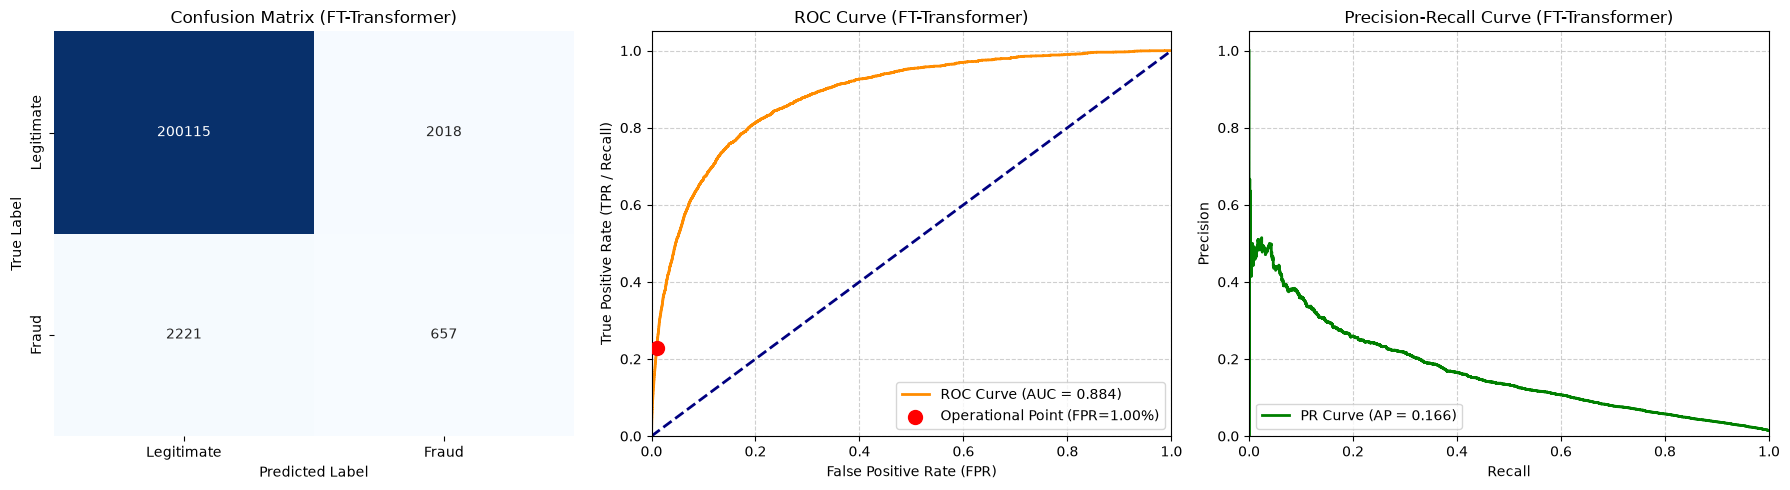

In [5]:
print("Evaluation report...")
evaluate_predictions(
    y_true=y_test,
    y_probs=test_probabilities,
    model_name="FT-Transformer"
)

In [7]:
import os
# Save the trained FT-Transformer weights
MODELS_DIR = Path(PROJECT_ROOT) / "models"
os.makedirs(MODELS_DIR, exist_ok=True)

ft_save_path = MODELS_DIR / "ft_transformer_model.pkl"
model.save_params(f_params=str(ft_save_path))
print(f"FT-Transformer architecture weights saved to: {ft_save_path}")

FT-Transformer architecture weights saved to: C:\Users\shubh\projects\FairFraud\models\ft_transformer_model.pkl
